# 1. Initial preparation, importing libraries and dataset

In [220]:
#data handling base
import pandas as pd
import numpy as np

#language identification
from langdetect import detect_langs, DetectorFactory

#feature engineering
import re
import spacy 
from spacy.matcher import Matcher
from collections import Counter
import torch
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModelForSequenceClassification

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, MinMaxScaler


#visualization
import seaborn as sns
import matplotlib.pyplot as plt

In [221]:
#import dataset from csv file
df = pd.read_csv('twcs.csv', encoding='utf-8')

In [222]:
#column info
print(df.info())
print(f'\n{'*'* 40}\n')
print('number of NA values:')
print(df.isna().sum())
print(f'\n{'*'* 40}\n')
print('number of duplicate rows:', df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2811774 entries, 0 to 2811773
Data columns (total 7 columns):
 #   Column                   Dtype  
---  ------                   -----  
 0   tweet_id                 int64  
 1   author_id                object 
 2   inbound                  bool   
 3   created_at               object 
 4   text                     object 
 5   response_tweet_id        object 
 6   in_response_to_tweet_id  float64
dtypes: bool(1), float64(1), int64(1), object(4)
memory usage: 131.4+ MB
None

****************************************

number of NA values:
tweet_id                         0
author_id                        0
inbound                          0
created_at                       0
text                             0
response_tweet_id          1040629
in_response_to_tweet_id     794335
dtype: int64

****************************************

number of duplicate rows: 0


# 2. Data preparation and cleaning

In [223]:
#thread root:
def get_thread_root(tweet_id, parent_map):
    visited = set()
    while tweet_id in parent_map and tweet_id not in visited:
        visited.add(tweet_id)
        tweet_id = parent_map[tweet_id]
    return tweet_id

In [224]:
# pull all tweets belonging to those threads
parent_map = df.dropna(subset=['in_response_to_tweet_id']).set_index('tweet_id')['in_response_to_tweet_id'].to_dict()

df['thread_root'] = df['tweet_id'].apply(lambda x: get_thread_root(x, parent_map))

df['is_root'] = df['in_response_to_tweet_id'].isna()
df['is_end'] = df['response_tweet_id'].isna()
print(df['thread_root'].nunique())

798012


In [225]:
nonthreads = df[df['response_tweet_id'].isna() & df['in_response_to_tweet_id'].isna()]
nonthreads

,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id,thread_root,is_root,is_end


In [226]:
# All tweet IDs present in the dataset
parent_ids_in_data = set(df['tweet_id'])

# All parent references (drop NaN roots)
orphaned = df['in_response_to_tweet_id'].dropna()

# Boolean mask: True if parent is missing
mask = ~orphaned.isin(parent_ids_in_data)

orphan_count = mask.sum()
print(f'Orphaned threads: {orphan_count} ({orphan_count/len(df)*100:.1f}%)')

# Create a dataframe of orphaned replies
df_orphans = df.loc[df['in_response_to_tweet_id'].isin(orphaned[mask])]
df_orphans.head()


Orphaned threads: 3862 (0.1%)


,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id,thread_root,is_root,is_end
138,222,115760,True,Tue Oct 31 19:05:30 +0000 2017,@108162 @115761 @ATVIAssist tried that there w...,221,223.000,223.000,False,False
1035,1621,AzureSupport,False,Tue Oct 31 22:11:47 +0000 2017,@116051 Sorry to hear your having trouble. Cou...,1620,1622.000,1622.000,False,False
2817,3745,AmazonHelp,False,Tue Oct 31 22:36:29 +0000 2017,"@116616 David, te recomendamos no compartir in...",3744,3746.000,3746.000,False,False
2848,3777,116625,True,Tue Oct 31 22:53:05 +0000 2017,@AppleSupport I've also forced the app to clos...,3775,3779.000,3779.000,False,False
4082,5530,Ask_Spectrum,False,Tue Oct 31 23:08:39 +0000 2017,@117003 Please remove that from public. I have...,5529,5531.000,5531.000,False,False


In [227]:
orphan_thr = df_orphans['thread_root']
bfr = len(df)
df = df.loc[~df['thread_root'].isin(orphan_thr)]
aftr = len(df)
print(f'removed {bfr - aftr} tweets')

removed 15909 tweets


In [228]:
#find root tweets
sampled_roots = df['thread_root'].drop_duplicates().sample(n=20000, random_state=42)
#Instead of sampling dataset directly, I sampled roots, otherwise threads would be truncated

df_sample = df[df['thread_root'].isin(sampled_roots)].copy()
df_sample.head(5)

,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id,thread_root,is_root,is_end
74,152,ChipotleTweets,False,Tue Oct 31 22:10:33 +0000 2017,"@115734 I mean, Boorito is basically the adult...",NaN,153.000,153.000,False,True
75,153,115734,True,Tue Oct 31 22:01:03 +0000 2017,Happy Halloween! Since I'm too old to trick or...,152,NaN,153.000,True,False
109,192,marksandspencer,False,Tue Oct 31 21:48:52 +0000 2017,@115748 We've let our team know we can do bett...,NaN,193.000,193.000,False,True
110,193,115748,True,Tue Oct 31 17:58:45 +0000 2017,"‘Ere @marksandspencer, never mind avocado 🥑 - ...",192,NaN,193.000,True,False
632,1162,TMobileHelp,False,Tue Oct 31 22:22:53 +0000 2017,"@115915 Well, we'd be happy to take a look at ...",NaN,1163.000,1163.000,False,True


In [229]:
df_sample['created_at'] = pd.to_datetime(df_sample['created_at'], format='%a %b %d %H:%M:%S %z %Y', errors='coerce')
df_sample = df_sample.sort_values(['thread_root', 'created_at'])
df_sample['turn_index'] = df_sample.groupby('thread_root').cumcount()
df_sample.info()

<class 'pandas.core.frame.DataFrame'>
Index: 71386 entries, 75 to 2811748
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype              
---  ------                   --------------  -----              
 0   tweet_id                 71386 non-null  int64              
 1   author_id                71386 non-null  object             
 2   inbound                  71386 non-null  bool               
 3   created_at               71386 non-null  datetime64[ns, UTC]
 4   text                     71386 non-null  object             
 5   response_tweet_id        45151 non-null  object             
 6   in_response_to_tweet_id  51386 non-null  float64            
 7   thread_root              71386 non-null  float64            
 8   is_root                  71386 non-null  bool               
 9   is_end                   71386 non-null  bool               
 10  turn_index               71386 non-null  int64              
dtypes: bool(3), datetime64[ns, UTC

In [230]:
valid_threads = (
    df_sample.groupby("thread_root")["inbound"]
    .apply(lambda x: x.any() and (~x).any())
)
valid_thread_ids = valid_threads[valid_threads].index

df_sample = df_sample[df_sample["thread_root"].isin(valid_thread_ids)]
df_sample.info()

<class 'pandas.core.frame.DataFrame'>
Index: 71384 entries, 75 to 2811748
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype              
---  ------                   --------------  -----              
 0   tweet_id                 71384 non-null  int64              
 1   author_id                71384 non-null  object             
 2   inbound                  71384 non-null  bool               
 3   created_at               71384 non-null  datetime64[ns, UTC]
 4   text                     71384 non-null  object             
 5   response_tweet_id        45150 non-null  object             
 6   in_response_to_tweet_id  51385 non-null  float64            
 7   thread_root              71384 non-null  float64            
 8   is_root                  71384 non-null  bool               
 9   is_end                   71384 non-null  bool               
 10  turn_index               71384 non-null  int64              
dtypes: bool(3), datetime64[ns, UTC

In [231]:
DetectorFactory.seed = 42

def thread_lang_conf(group):
    # detect language on concatenated customer text for the whole thread
    cust_text = " ".join(group[group["inbound"] == True]["text"].astype(str))
    try:
        top = detect_langs(cust_text)[0]
        return pd.Series({"lang": top.lang, "conf": top.prob})
    except:
        return pd.Series({"lang": "unknown", "conf": 0.0})


# detect per thread
lang_conf = df_sample.groupby("thread_root").apply(thread_lang_conf)

# only drop threads confidently detected as non-english
drop_ids = lang_conf[(lang_conf["lang"] != "en") & (lang_conf["conf"] > 0.90)].index

before = df_sample["thread_root"].nunique()
df_sample = df_sample[~df_sample["thread_root"].isin(drop_ids)].copy()
after = df_sample["thread_root"].nunique()

print(f"threads: {before} -> {after} ({before - after} non-english dropped)")

threads: 19999 -> 19231 (768 non-english dropped)


C:\Users\Asus Tuf\AppData\Local\Temp\ipykernel_18764\3337528555.py:14: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  lang_conf = df_sample.groupby("thread_root").apply(thread_lang_conf)


# 3. Descriptive analysis

In [232]:
# pd.set_option('display.max_colwidth', 100)
# df_sample.style.set_properties(**{'text-align': 'left'})
# print(df_sample["text"].head(30))
# pd.set_option('display.max_colwidth', 30)
pd.set_option('display.float_format', lambda x: '%.3f' % x)

### 3.1 Check if sample doesn't differ from dataset


In [233]:
#comparing the percentage of root and end tweets in sample vs full dataset
nullratio = df_sample['in_response_to_tweet_id'].isna().sum() / df_sample.shape[0] * 100
print('sample root tweet percentage = ', nullratio,'%')

nullratio1 = df['in_response_to_tweet_id'].isna().sum() / df.shape[0] * 100
print('root tweet percentage        = ',nullratio1,'%')

nullratio2 = df_sample['response_tweet_id'].isna().sum() / df_sample.shape[0] * 100
print('sample end tweet percentage  = ',nullratio2,'%')

nullratio3 = df['response_tweet_id'].isna().sum() / df.shape[0] * 100
print('end tweet percentage         = ',nullratio3,'%')

sample root tweet percentage =  28.06707726436849 %
root tweet percentage        =  28.411064196590324 %
sample end tweet percentage  =  36.92898216527044 %
end tweet percentage         =  37.04552973766616 %


### 3.2 Author statistics

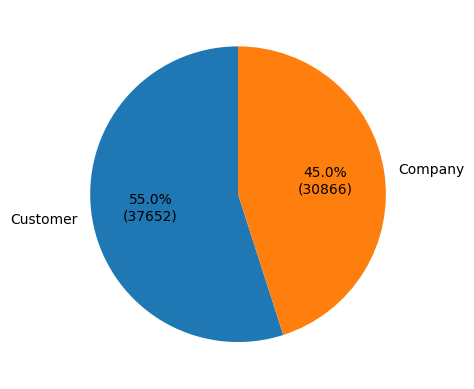

In [234]:
def make_autopct(values):
    def my_autopct(pct):
        total = sum(values)
        val = int(round(pct * total / 100.0))
        return f'{pct:.1f}%\n({val:d})'
    return my_autopct

inbound = df_sample['inbound'].value_counts()
plt.pie(x=inbound, labels=['Customer', 'Company'], autopct=make_autopct(inbound), startangle = 90)
plt.show()

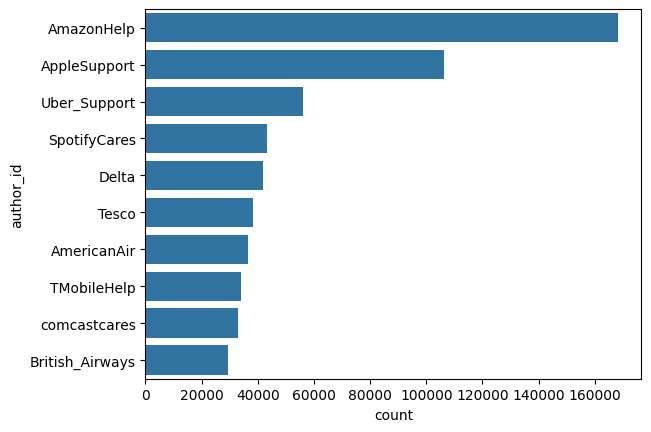

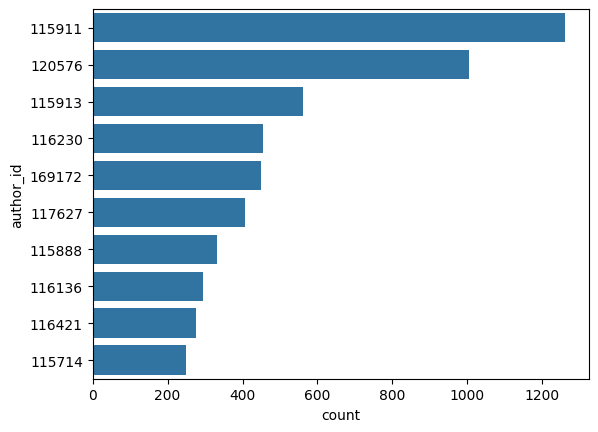

In [235]:
#filter only companies
companies = df[(df['inbound'] == False)]

#top 10 by count
order = companies['author_id'].value_counts().iloc[:10].index

#visualization
sns.countplot(companies['author_id'], order = order)
plt.show()

companies.head(5)

users = df[(df['inbound'] == True)]

order1 = users['author_id'].value_counts().iloc[:10].index

sns.countplot(users['author_id'], order = order1)
plt.show()

In [236]:
author_counts = (
    df.groupby('thread_root')['author_id']
    .nunique()
    .reset_index()
    .rename(columns={'author_id': 'n_distinct_authors'})
)

# Flag multi-party threads
author_counts['multi_party'] = author_counts['n_distinct_authors'] > 2

print(author_counts['n_distinct_authors'].value_counts().sort_index())
print(f"\nMulti-party threads: {author_counts['multi_party'].sum()}")

n_distinct_authors
1          62
2      737641
3       44197
4        6918
5        2088
        ...  
231         1
283         2
337         1
620         1
973         1
Name: count, Length: 120, dtype: int64

Multi-party threads: 56632


### 3.3 Text statistics

In [237]:
df_sample['chr_length'] = df_sample['text'].str.len()
sns.histplot(df_sample['chr_length'], bins = 40)

plt.title('Text character length distribution')
plt.xlabel('length')
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

### 3.4 Thread statistics

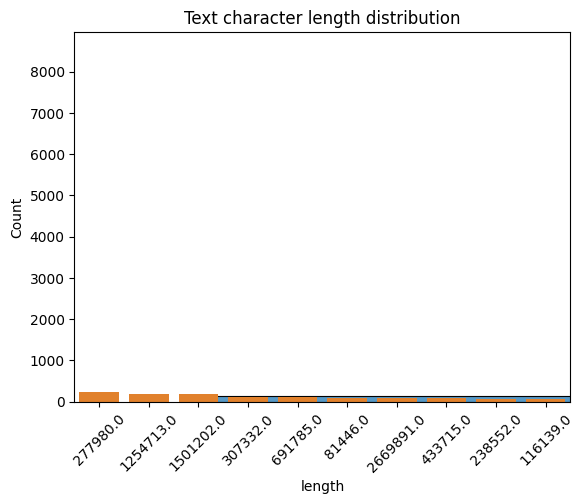

In [238]:
order2 = df_sample['thread_root'].value_counts().iloc[:10].index
sns.countplot(x = 'thread_root', data = df_sample, order = order2)
plt.xticks(rotation=45)
plt.show()

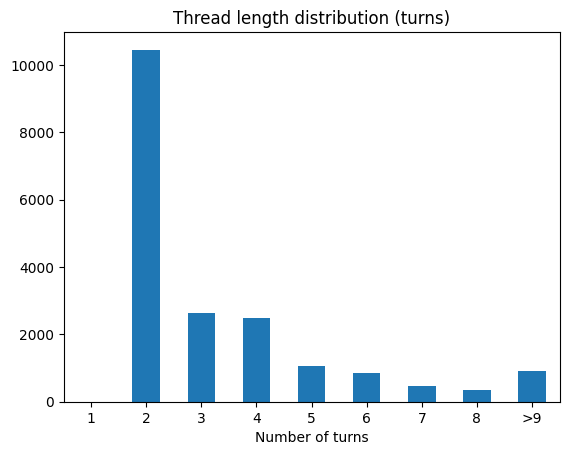

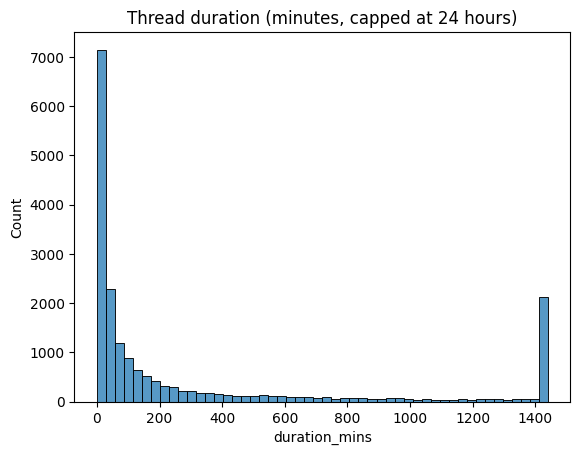

In [239]:
thread_stats = df_sample.groupby('thread_root').agg(
    turn_count=('tweet_id', 'count'),
    duration_mins=('created_at', lambda x: (x.max() - x.min()).total_seconds() / 60)
).reset_index()


bins1 = [1, 2, 3, 4, 5, 6, 7, 8, 9, np.inf]
labels1 = ['1', '2', '3', '4', '5', '6', '7', '8', '>9']
thr = thread_stats['turn_count']


thr_bin = pd.cut(thr, bins=bins1, labels=labels1, right=False)
counts = thr_bin.value_counts().reindex(labels1)
counts.plot(kind='bar')

plt.title('Thread length distribution (turns)')
plt.xlabel('Number of turns')
plt.xticks(rotation = 0)
plt.show()

sns.histplot(thread_stats['duration_mins'].clip(upper=1440), bins=50)
plt.title('Thread duration (minutes, capped at 24 hours)')
plt.show()

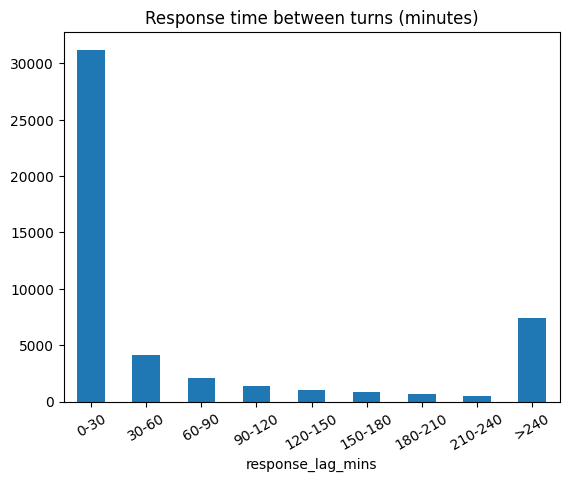

In [240]:
df_sample['response_lag_mins'] = df_sample.groupby('thread_root')['created_at'].diff().dt.total_seconds() / 60
lag = df_sample['response_lag_mins'].dropna()

bins = [0, 30, 60, 90, 120, 150, 180, 210, 240, np.inf]
labels = ['0-30', '30-60', '60-90', '90-120', '120-150', '150-180', '180-210', '210-240', '>240']

lag_binned = pd.cut(lag, bins=bins, labels=labels, right=False)
counts = lag_binned.value_counts().reindex(labels)
counts.plot(kind='bar')
plt.title('Response time between turns (minutes)')
plt.xticks(rotation=30)
plt.show()

In [241]:
thread_stats.describe()


,thread_root,turn_count,duration_mins
count,19231.000,19231.000,19231.000
mean,1572013.640,3.563,1704.884
std,850557.409,4.288,26328.748
min,153.000,2.000,0.183
25%,841968.000,2.000,13.992
50%,1644660.000,2.000,61.433
75%,2285980.000,4.000,363.667
max,2987928.000,245.000,1738020.517


In [242]:
thre = thread_stats[(thread_stats['duration_mins'] > 2880)]
df_sample2 = df_sample[df_sample['thread_root'].isin(thre['thread_root'])]
df_sample2

,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id,thread_root,is_root,is_end,turn_index,chr_length,response_lag_mins
721,1260,115939,True,2017-10-30 01:02:34+00:00,@hulu_support @115940 my wife and I hate the...,1258,NaN,1260.000,True,False,0,126,NaN
717,1258,hulu_support,False,2017-10-31 22:28:55+00:00,@115939 Oh no! Any aspect about navigation tha...,1259,1260.000,1260.000,False,False,1,131,2726.350
718,1259,115939,True,2017-11-04 12:35:35+00:00,@hulu_support Getting to the lists of episodes...,1261,1258.000,1260.000,False,False,2,148,5166.667
719,1261,hulu_support,False,2017-11-06 23:42:12+00:00,@115939 Apologies for the difficulties! That w...,1262,1259.000,1260.000,False,False,3,136,3546.617
720,1262,115939,True,2017-11-07 00:20:46+00:00,@hulu_support Thanks,NaN,1261.000,1260.000,False,True,4,20,38.567
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2787967,2964467,817920,True,2017-10-19 08:10:46+00:00,@TfL please can you include hand rails for sho...,2964466,NaN,2964467.000,True,False,0,94,NaN
2787966,2964466,817920,True,2017-11-15 22:21:42+00:00,@TfL please can I have a follow up on this tweet?,2964465,2964467.000,2964467.000,False,False,1,49,39730.933
2787965,2964465,TfL,False,2017-11-29 20:37:30+00:00,"@817920 Hi Lucy, sorry for the delay respondin...",NaN,2964466.000,2964467.000,False,True,2,261,20055.800
2791579,2968140,818787,True,2017-11-27 13:18:19+00:00,@AirAsiaSupport hi! Is there an update on flig...,2968139,NaN,2968140.000,True,False,0,137,NaN


In [243]:
thre['duration_mins'].value_counts().sort_index(ascending=False)

duration_mins
1738020.517    1
1340663.100    1
1045114.017    1
1044831.183    1
1039501.250    1
              ..
2884.350       1
2884.283       1
2883.683       1
2883.350       1
2882.800       1
Name: count, Length: 1194, dtype: int64

In [244]:
df_sample2.describe()

,tweet_id,in_response_to_tweet_id,thread_root,turn_index,chr_length,response_lag_mins
count,8742.000,7547.000,8742.000,8742.000,8742.000,7547.000
mean,1270451.539,1187765.902,1123633.092,15.453,115.008,3702.457
std,846785.070,831698.890,821068.097,33.531,52.553,39454.141
min,1258.000,1258.000,1260.000,0.000,7.000,0.000
25%,488025.000,429915.500,347205.250,1.000,78.000,4.758
50%,1166221.500,1063363.000,969788.000,4.000,117.000,39.050
75%,1992317.750,1866123.500,1737997.000,11.000,141.000,954.300
max,2984490.000,2978305.000,2968140.000,244.000,452.000,1735649.400


In [245]:
df_sample.describe()

,tweet_id,in_response_to_tweet_id,thread_root,turn_index,chr_length,response_lag_mins
count,68518.000,49287.000,68518.000,68518.000,68518.000,49287.000
mean,1511548.296,1472925.822,1486380.293,3.862,114.019,665.219
std,856170.371,859075.777,860188.850,13.252,51.828,15494.467
min,152.000,153.000,153.000,0.000,2.000,0.000
25%,773426.250,735103.000,740844.000,0.000,78.000,2.983
50%,1523909.500,1455772.000,1487722.000,1.000,116.000,12.800
75%,2246467.750,2218943.000,2227481.000,3.000,140.000,81.567
max,2987928.000,2987928.000,2987928.000,244.000,452.000,1735649.400


In [246]:
with pd.option_context("display.max_rows", 1000):
    display(df_sample[df_sample['thread_root'] == 625855])

,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id,thread_root,is_root,is_end,turn_index,chr_length,response_lag_mins


In [247]:
thread_stats.describe()

,thread_root,turn_count,duration_mins
count,19231.000,19231.000,19231.000
mean,1572013.640,3.563,1704.884
std,850557.409,4.288,26328.748
min,153.000,2.000,0.183
25%,841968.000,2.000,13.992
50%,1644660.000,2.000,61.433
75%,2285980.000,4.000,363.667
max,2987928.000,245.000,1738020.517


In [248]:
(thread_stats['turn_count'] > 4).mean()

np.float64(0.18943372679527845)

### 3.5 Temporal statistics

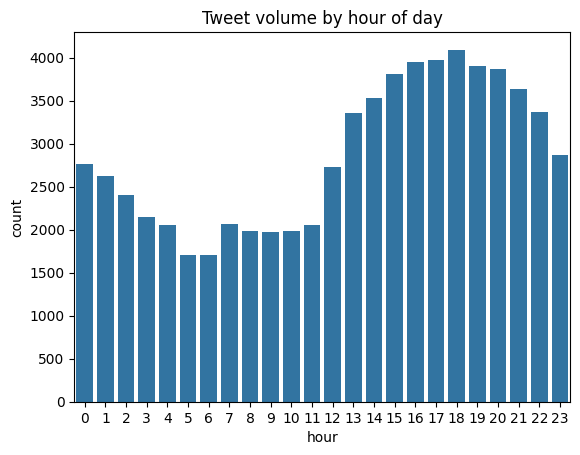

In [249]:
df_sample['hour'] = df_sample['created_at'].dt.hour
sns.countplot(x='hour', data=df_sample)
plt.title('Tweet volume by hour of day')
plt.show()

In [250]:
zero_lag = df_sample[(df_sample['response_lag_mins'] == 0) & (df_sample['inbound'] == True)]
with pd.option_context('display.max_colwidth', 100):
    display (df_sample[(df_sample['thread_root'].isin(zero_lag['thread_root']))].head(30))


,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id,thread_root,is_root,is_end,turn_index,chr_length,response_lag_mins,hour
301108,344909,198058,True,2017-10-08 01:16:34+00:00,@115873 I was charged twice for my Uber trip and your customer service isn’t emailing me back!!!...,344907,NaN,344909.000,True,False,0,135,NaN,1
301107,344907,Uber_Support,False,2017-10-08 01:20:15+00:00,@198058 We can definitely take a closer look! Please send us your email connected to your accoun...,"344906,344908",344909.000,344909.000,False,False,1,127,3.683,1
301106,344906,198058,True,2017-10-08 01:22:54+00:00,@Uber_Support what’s your email?,344905,344907.000,344909.000,False,False,2,32,2.650,1
706596,344908,198058,True,2017-10-08 01:22:54+00:00,@Uber_Support I sent u an email from my account,NaN,344907.000,344909.000,False,True,3,47,0.000,1
301105,344905,198058,True,2017-10-08 01:23:52+00:00,@Uber_Support I sent u a help request on my Uber app but haven’t gotten a response?,344904,344906.000,344909.000,False,False,4,83,0.967,1
301104,344904,Uber_Support,False,2017-10-08 02:04:34+00:00,@198058 Can you please DM us the email on your account so we can check on the status of your mes...,NaN,344905.000,344909.000,False,True,5,109,40.700,2
325484,372990,204391,True,2017-10-08 22:08:05+00:00,@AmericanAir never take this company !! it's the worse I know,372988,NaN,372990.000,True,False,0,61,NaN,22
325483,372988,AmericanAir,False,2017-10-08 22:46:41+00:00,@204391 We sense you're upset at us and we'd love to help. What's going on?,"372987,372989",372990.000,372990.000,False,False,1,75,38.600,22
740601,372989,204391,True,2017-10-08 22:48:19+00:00,@AmericanAir it's the second flight that is late in just one week. It's that normal ?,NaN,372988.000,372990.000,False,True,2,85,1.633,22
325482,372987,204391,True,2017-10-08 22:50:09+00:00,@AmericanAir If you want to help me so just give me an upgrade,372986,372988.000,372990.000,False,False,3,62,1.833,22


In [251]:
root_tweets = df_sample[df_sample['tweet_id'] == df_sample['thread_root']]
print(root_tweets['inbound'].value_counts())

inbound
True     19067
False      164
Name: count, dtype: int64


In [252]:
customer_roots = root_tweets[root_tweets['inbound'] == True]['tweet_id']
df_sample = df_sample[df_sample['thread_root'].isin(customer_roots)]

# 4. Linguistic Features

In [253]:
nlp = spacy.load("en_core_web_sm")


INBOUND_INTENT = {
    "cancel", "cancelled", "cancelling", "cancellation",
    "sue", "suing", "lawsuit", "lawyer", "legal",
    "ombudsman", "ofcom", "regulator", "watchdog",
    "chargeback", "refund", "reimbursement",
    "switching", "leaving", "elsewhere",
}

INBOUND_FRUSTRATION = {
    "unacceptable", "ridiculous", "disgusting", "outrageous",
    "appalling", "pathetic", "terrible", "horrible",
    "useless", "incompetent", "shameful", "shocking",
    "furious", "livid", "angry", "disgusted",
    "scam", "fraud", "lied", "liar", "cheated",
}

OUTBOUND_DEFLECTION = {
    "unable", "cannot", "policy", "procedure",
    "terms", "conditions", "unfortunately",
    "different", "department", "another", "team",
    "contact", "reach",
}

OUTBOUND_BUREAUCRATIC = {
    "kindly", "advised", "note", "patience",
    "understand", "appreciate", "bear",
    "investigate", "flag", "raise", "pass",
}

OUTBOUND_FORMAL_VOCAB = {
    "furthermore", "however", "subsequently", "regarding",
    "henceforth", "accordance", "hereby", "therein",
    "aforementioned", "notwithstanding", "whilst",
    "therefore", "thus", "hence", "wherein",
}

CONTRACTIONS = {
    "i'm", "we'll", "can't", "won't", "didn't", "we're",
    "you're", "it's", "that's", "there's", "don't", "isn't",
    "they're", "i'll", "i've", "you've", "we've",
}

INFORMAL_ABBREVIATIONS = {
    "dm", "asap", "fyi", "tbh", "imo",
    "btw", "ngl", "ty", "thx", "pls", "plz",
}

NEGATIVE_EMOJIS = {
    "😡", "😤", "🤬", "😠", "😒", "🙄", "💀", "😑", 
    "😫", "😩", "😣", "🖕", "😖", "😤"
}

NEGATION_TOKENS = {
    "not", "no", "never", "neither", "nor", "n't", "cant",       
    "won't", "wont", "didn't", "didnt", "don't", "dont",
    "isn't", "isnt", "wasn't", "wasnt", "couldn't", "couldnt", "shouldnt", "shouldn't"
}

In [254]:
def build_category_matchers(nlp):
    matchers = {}
    for name, termset in [
        ("inbound_intent",        INBOUND_INTENT),
        ("inbound_frustration",   INBOUND_FRUSTRATION),
        ("outbound_deflection",   OUTBOUND_DEFLECTION),
        ("outbound_bureaucratic", OUTBOUND_BUREAUCRATIC),
        ("outbound_formal_vocab", OUTBOUND_FORMAL_VOCAB),
    ]:
        m = Matcher(nlp.vocab)
        for term in termset:
            pattern = [{"LOWER": w} for w in term.split()]
            m.add(term, [pattern])
        matchers[name] = m
    return matchers

category_matchers = build_category_matchers(nlp)

In [255]:
def formality_score(doc) -> float:
    tokens = [t for t in doc if not t.is_space and not t.is_punct]
    if not tokens:
        return 50.0

    total = len(tokens)
    pos_counts = Counter(t.pos_ for t in tokens)

    noun = pos_counts.get("NOUN", 0) + pos_counts.get("PROPN", 0)
    adj  = pos_counts.get("ADJ", 0)
    prep = pos_counts.get("ADP", 0) 
    art  = pos_counts.get("DET", 0)  
    pron = pos_counts.get("PRON", 0)
    verb = pos_counts.get("VERB", 0) + pos_counts.get("AUX", 0)
    adv  = pos_counts.get("ADV", 0)
    intj = pos_counts.get("INTJ", 0)

    f = ((noun + adj + prep + art - pron - verb - adv - intj)
         / total * 100 + 100) / 2

    return round(f, 4)


In [256]:
def informal_markers(doc, text: str) -> dict:
    tokens_lower = [t.lower_ for t in doc if not t.is_space]

    return {
        "contraction_count":  sum(1 for t in tokens_lower if t in CONTRACTIONS),
        "abbreviation_count": sum(1 for t in tokens_lower if t in INFORMAL_ABBREVIATIONS),
        "has_exclamation":    int("!" in text),
        "has_ellipsis":       int("..." in text),
    }

In [257]:
def extract_spacy_features(text: str, is_inbound: bool, doc=None) -> dict:
    if doc is None:
        doc = nlp(text)

    tokens       = [t for t in doc if not t.is_space]
    alpha_tokens = [t for t in tokens if t.is_alpha]

    token_count  = len(tokens)
    punct_count  = sum(1 for t in tokens if t.is_punct)
    upper_count  = sum(1 for t in alpha_tokens if t.text.isupper() and len(t.text) > 1)
    caps_ratio   = upper_count / len(alpha_tokens) if alpha_tokens else 0.0

    # Negation 
    has_negation = int(any(t.lower_ in NEGATION_TOKENS for t in tokens))

    # POS counts 
    pos_counts = Counter(t.pos_ for t in tokens)
    verb_count = pos_counts.get("VERB", 0)
    adj_count  = pos_counts.get("ADJ", 0)
    noun_count = pos_counts.get("NOUN", 0)

    # NER 
    ner_counts  = Counter(ent.label_ for ent in doc.ents)
    has_money   = int(ner_counts.get("MONEY", 0) > 0)
    has_org     = int(ner_counts.get("ORG", 0) > 0)

    # Direction-exclusive features 
    if is_inbound:

        # category flags
        has_intent      = int(len(category_matchers["inbound_intent"](doc)) > 0)
        has_frustration = int(len(category_matchers["inbound_frustration"](doc)) > 0)
        has_deflection  = 0
        has_bureaucratic= 0

        # negative emoji
        has_negative_emoji = int(any(ch in NEGATIVE_EMOJIS for ch in text))

        # formality
        f_score             = None
        has_formal_vocab    = 0
        contraction_count   = 0
        abbreviation_count  = 0
        has_passive         = 0
        uses_we_not_i       = 0

    else:

        # Category flags
        has_intent      = 0
        has_frustration = 0
        has_deflection  = int(len(category_matchers["outbound_deflection"](doc)) > 0)
        has_bureaucratic= int(len(category_matchers["outbound_bureaucratic"](doc)) > 0)

        # Negative emoji
        has_negative_emoji = 0

        # Formality score (continuous)
        f_score = formality_score(doc)

        # Formal vocabulary flag
        has_formal_vocab = int(
            len(category_matchers["outbound_formal_vocab"](doc)) > 0
        )

        # Informal markers
        tokens_lower       = [t.lower_ for t in tokens]
        contraction_count  = sum(1 for t in tokens_lower if t in CONTRACTIONS)
        abbreviation_count = sum(1 for t in tokens_lower if t in INFORMAL_ABBREVIATIONS)

        # Passive voice
        has_passive = int(any(t.dep_ == "auxpass" for t in doc))

        pronoun_tokens = [t for t in doc
                          if t.pos_ == "PRON" and t.lower_ in {"i", "we"}]
        uses_we_not_i  = int(
            len(pronoun_tokens) > 0 and
            all(t.lower_ == "we" for t in pronoun_tokens)
        )

    return {
        # Surface
        "token_count":          token_count,
        "punct_count":          punct_count,
        "caps_ratio":           round(caps_ratio, 4),
        # Linguistic
        "has_negation":         has_negation,
        "verb_count":           verb_count,
        "adj_count":            adj_count,
        "noun_count":           noun_count,
        # NER
        "has_money_entity":     has_money,
        "has_org_entity":       has_org,
        # Inbound-exclusive
        "has_intent_term":      has_intent,
        "has_frustration_term": has_frustration,
        "has_negative_emoji":   has_negative_emoji,
        # Outbound-exclusive
        "has_deflection_term":   has_deflection,
        "has_bureaucratic_term": has_bureaucratic,
        "formality_score":       f_score,
        "has_formal_vocab":      has_formal_vocab,
        "contraction_count":     contraction_count,
        "abbreviation_count":    abbreviation_count,
        "has_passive":           has_passive,
        "uses_we_not_i":         uses_we_not_i,
    }

In [258]:
def extract_features_batch(df: pd.DataFrame,
                            text_col: str = "text",
                            inbound_col: str = "inbound",
                            batch_size: int = 256,
                            n_process: int = 1) -> pd.DataFrame:

    texts    = df[text_col].fillna("").tolist()
    inbounds = df[inbound_col].tolist()
    records  = []

    docs = nlp.pipe(texts, batch_size=batch_size, n_process=n_process)

    for doc, is_inbound in zip(docs, inbounds):
        records.append(
            extract_spacy_features(doc.text, is_inbound=bool(is_inbound), doc=doc)
        )

    features_df = pd.DataFrame(records, index=df.index)
    return pd.concat([df, features_df], axis=1)

In [259]:
print(f'spaCy extraction on {len(df_sample)} tweets')
df_ft1 = extract_features_batch(df_sample, text_col="text")

spaCy extraction on 66304 tweets


In [260]:
df_ft1

,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id,thread_root,is_root,is_end,...,has_frustration_term,has_negative_emoji,has_deflection_term,has_bureaucratic_term,formality_score,has_formal_vocab,contraction_count,abbreviation_count,has_passive,uses_we_not_i
75,153,115734,True,2017-10-31 22:01:03+00:00,Happy Halloween! Since I'm too old to trick or...,152,NaN,153.000,True,False,...,0,0,0,0,NaN,0,0,0,0,0
74,152,ChipotleTweets,False,2017-10-31 22:10:33+00:00,"@115734 I mean, Boorito is basically the adult...",NaN,153.000,153.000,False,True,...,0,0,0,0,66.667,0,0,0,0,0
110,193,115748,True,2017-10-31 17:58:45+00:00,"‘Ere @marksandspencer, never mind avocado 🥑 - ...",192,NaN,193.000,True,False,...,0,0,0,0,NaN,0,0,0,0,0
109,192,marksandspencer,False,2017-10-31 21:48:52+00:00,@115748 We've let our team know we can do bett...,NaN,193.000,193.000,False,True,...,0,0,1,0,33.333,0,0,0,0,1
633,1163,115915,True,2017-10-31 22:20:14+00:00,T-Mobile So Bs My Internet Stop Working For 3 ...,1162,NaN,1163.000,True,False,...,0,0,0,0,NaN,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2811343,2987528,VirginAmerica,False,2017-10-31 21:48:00+00:00,@270982 Your awesome! Thanks for flying with u...,NaN,2987529.000,2987529.000,False,True,...,0,0,0,0,50.000,0,0,0,0,0
2811726,2987905,823855,True,2017-11-22 07:15:51+00:00,£250 train fare for my round trip to London to...,2987904,NaN,2987905.000,True,False,...,0,0,0,0,NaN,0,0,0,0,0
2811725,2987904,VirginTrains,False,2017-11-22 07:18:22+00:00,"@823855 Which service are you on, Fiona? ^CB",NaN,2987905.000,2987905.000,False,True,...,0,0,0,0,68.750,0,0,0,0,0
2811749,2987928,385866,True,2017-11-29 22:20:52+00:00,Ahh spent £120 yesterday and now Argos have th...,2987927,NaN,2987928.000,True,False,...,0,0,0,0,NaN,0,0,0,0,0


In [261]:
cols = ['has_intent_term', 'has_frustration_term', 'has_deflection_term', 'has_bureaucratic_term', 'has_negative_emoji', 'has_money_entity', 'has_org_entity']
df_ft1[cols].apply(pd.Series.value_counts)

,has_intent_term,has_frustration_term,has_deflection_term,has_bureaucratic_term,has_negative_emoji,has_money_entity,has_org_entity
0,64918,65124,61869,63645,65436,64537,42901
1,1386,1180,4435,2659,868,1767,23403


In [262]:
df_ft1.info()

<class 'pandas.core.frame.DataFrame'>
Index: 66304 entries, 75 to 2811748
Data columns (total 34 columns):
 #   Column                   Non-Null Count  Dtype              
---  ------                   --------------  -----              
 0   tweet_id                 66304 non-null  int64              
 1   author_id                66304 non-null  object             
 2   inbound                  66304 non-null  bool               
 3   created_at               66304 non-null  datetime64[ns, UTC]
 4   text                     66304 non-null  object             
 5   response_tweet_id        41803 non-null  object             
 6   in_response_to_tweet_id  47237 non-null  float64            
 7   thread_root              66304 non-null  float64            
 8   is_root                  66304 non-null  bool               
 9   is_end                   66304 non-null  bool               
 10  turn_index               66304 non-null  int64              
 11  chr_length               66304

In [263]:
df_ft1[df_ft1['has_negative_emoji'] == 1]

,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id,thread_root,is_root,is_end,...,has_frustration_term,has_negative_emoji,has_deflection_term,has_bureaucratic_term,formality_score,has_formal_vocab,contraction_count,abbreviation_count,has_passive,uses_we_not_i
682,1223,115929,True,2017-10-31 22:08:55+00:00,@SouthwestAir is down on the my account page 😑😑,1221,NaN,1223.000,True,False,...,0,1,0,0,NaN,0,0,0,0,0
6343,9444,117691,True,2017-10-31 23:46:11+00:00,iPhone X order cancelled. Email e-sig = bad UX...,9443,NaN,9444.000,True,False,...,0,1,0,0,NaN,0,0,0,0,0
21140,27243,121966,True,2017-10-31 17:51:42+00:00,"nahhh, bt why didn't i think of this? 🙄 @Gregg...",27242,NaN,27243.000,True,False,...,0,1,0,0,NaN,0,0,0,0,0
22210,28569,122253,True,2017-11-01 10:45:30+00:00,Feeling ever so slightly claustrophobic. This ...,28567,NaN,28569.000,True,False,...,0,1,0,0,NaN,0,0,0,0,0
25314,31991,123081,True,2017-11-01 12:21:35+00:00,Why do @115873 drivers insist on trying to dro...,31990,NaN,31991.000,True,False,...,0,1,0,0,NaN,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2798344,2974907,820453,True,2017-11-30 02:31:32+00:00,What is the point of @115821 prime when your p...,2974906,NaN,2974907.000,True,False,...,0,1,0,0,NaN,0,0,0,0,0
2799612,2976146,360922,True,2017-11-16 04:05:56+00:00,ever since i updated my phone to the 11.1.1 ap...,2976145,NaN,2976146.000,True,False,...,0,1,0,0,NaN,0,0,0,0,0
2799781,2976302,820837,True,2017-11-16 11:21:36+00:00,I need answers!!! @115858 this update has turn...,2976301,NaN,2976302.000,True,False,...,0,1,0,0,NaN,0,0,0,0,0
2811125,2987309,813843,True,2017-11-21 22:25:09+00:00,@115714 y’all need to send me my phone already...,2987308,NaN,2987309.000,True,False,...,0,1,0,0,NaN,0,0,0,0,0


# 5. Sentiment Features

In [264]:
def preprocess(text):
    text = re.sub(r"http\S+", "http", text)
    text = re.sub(r"@\w+", "@user", text)
    return text.strip()

In [265]:
def score_batch(texts, batch_size=32):
    results = []

    for i in range(0, len(texts), batch_size):
        batch = [preprocess(t) for t in texts[i : i + batch_size]]

        inputs = tokenizer(
            batch,
            return_tensors="pt",
            truncation=True,
            max_length=128,
            padding=True 
        ).to(device)

        with torch.no_grad():
            logits = model(**inputs).logits

        probs = F.softmax(logits, dim=1).cpu().numpy()

        for row in probs:
            results.append({
                "sentiment_neg": round(float(row[0]), 4),
                "sentiment_neu": round(float(row[1]), 4),
                "sentiment_pos": round(float(row[2]), 4),
            })

        if i % 5000 == 0:
            print(f"  done {i}/{len(texts)}")

    return results

In [266]:
MODEL = "cardiffnlp/twitter-roberta-base-sentiment"
tokenizer = AutoTokenizer.from_pretrained(MODEL)
model     = AutoModelForSequenceClassification.from_pretrained(MODEL)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model  = model.to(device)
model.eval()
print(f"running on: {device}")

# run on full dataset
texts  = df_ft1["text"].fillna("").tolist()
scores = score_batch(texts, batch_size=32)

scores_df      = pd.DataFrame(scores, index=df_ft1.index)
tweets_scored  = pd.concat([df_ft1, scores_df], axis=1)

print(tweets_scored.groupby("inbound")[["sentiment_neg", "sentiment_neu", "sentiment_pos"]].mean().round(3))

tweets_scored.to_csv("tweets_sentiment.csv", index=False)
print("saved -> tweets_sentiment.csv")

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 20099.06it/s]


running on: cpu
  done 0/66304
  done 20000/66304
  done 40000/66304
  done 60000/66304
         sentiment_neg  sentiment_neu  sentiment_pos
inbound                                             
False            0.138          0.507          0.355
True             0.462          0.351          0.187
saved -> tweets_sentiment.csv


In [267]:
out = tweets_scored[tweets_scored["inbound"] == False].copy()

print("--- high negative outbound ---")
print(out.nlargest(10, "sentiment_neg")[["text", "sentiment_neg"]].to_string())

print("\n--- outbound neg distribution ---")
print(out["sentiment_neg"].describe().round(3))
print("\noutbound tweets with neg > 0.5:", (out["sentiment_neg"] > 0.5).sum())
print("outbound tweets with neg > 0.3:", (out["sentiment_neg"] > 0.3).sum())

--- high negative outbound ---
                                                                                                                                              text  sentiment_neg
1236533                                                                  @272953 Hi, thanks for contacting us.  This doesn't sound good! :-(  *HML          0.963
179897                                             @166620 This doesn't sound good at all! How long have you been experiencing service issues? -JC          0.961
1616929  @532407 WARNING!!  DO NOT CALL - THEY HAVE NO AFFILIATION WITH YAHOO AND CANNOT HELP WITH YOUR PASSWORDS - FRAUD!! @14736 @twittersupport          0.961
1219427                                                                              @433673 That's not good at all! Internet or Tv services? ^DDG          0.950
9285                                                                                               @118656 That's not cool. Where did this happen?          0.9

In [268]:
inb = tweets_scored[tweets_scored["inbound"] == True].copy()

print("--- high negative inb ---")
print(inb.nlargest(10, "sentiment_neg")[["text", "sentiment_neg"]].to_string())
print("\n--- inb neg distribution ---")
print(inb["sentiment_neg"].describe().round(3))

print("\ninb tweets with neg > 0.5:", (inb["sentiment_neg"] > 0.5).sum())
print("inb tweets with neg > 0.3:", (inb["sentiment_neg"] > 0.3).sum())

--- high negative inb ---
                                                                                                                                                                                                                                      text  sentiment_neg
462830                                                                                                                             i am so tired being on the phone with @AmazonHelp customer care!!!!y'all useless and not helpful at all          0.985
457261   I fucking hate @115873 every single time I use It (which is almost every day) there is an issue either with the app glitching, the driver being crazy or unauthorized charges on my account. Customer service is BEYOND pathetic.          0.985
1545097                                                                                                                            I'm so disappointed in the horrible customer service I receieved at 2 @115911 stores this pas

In [269]:
# tweets_scored = pd.read_csv('tweets_sentiment.csv', encoding='utf-8')

In [270]:
tweets_scored["formality_score"] = tweets_scored["formality_score"].fillna(0.0)

In [271]:
pd.set_option('display.max_info_columns', 999)
tweets_scored.info()

<class 'pandas.core.frame.DataFrame'>
Index: 66304 entries, 75 to 2811748
Data columns (total 37 columns):
 #   Column                   Non-Null Count  Dtype              
---  ------                   --------------  -----              
 0   tweet_id                 66304 non-null  int64              
 1   author_id                66304 non-null  object             
 2   inbound                  66304 non-null  bool               
 3   created_at               66304 non-null  datetime64[ns, UTC]
 4   text                     66304 non-null  object             
 5   response_tweet_id        41803 non-null  object             
 6   in_response_to_tweet_id  47237 non-null  float64            
 7   thread_root              66304 non-null  float64            
 8   is_root                  66304 non-null  bool               
 9   is_end                   66304 non-null  bool               
 10  turn_index               66304 non-null  int64              
 11  chr_length               66304

# 6. Thread-level Feature Aggregation

In [272]:
def get_slope(neg, turns):
    # slope of customer negative sentiment over the convo
    if len(neg) < 2:
        return 0.0
    return round(float(np.polyfit(turns, neg, 1)[0]), 4)

In [273]:
def get_agent_sim(texts):
    # how similar are the agent replies to each other
    if len(texts) < 2:
        return 0.0
    try:
        tf  = TfidfVectorizer().fit_transform(texts)
        sim = cosine_similarity(tf)
        n   = sim.shape[0]
        vals = [sim[i][j] for i in range(n) for j in range(i+1, n)]
        return round(sum(vals) / len(vals), 4)
    except:
        return 0.0

In [274]:
rows = []

for tid, g in tweets_scored.groupby("thread_root"):
    inb = g[g["inbound"] == True].sort_values("turn_index")
    out = g[g["inbound"] == False].sort_values("turn_index")

    d = {}
    d["thread_root"] = tid
    d["turn_count"]  = len(g)
    d["inb_turns"]   = len(inb)
    d["out_turns"]   = len(out)

    # customer sentiment
    d["neg_ratio"]               = round(float((inb["sentiment_neg"] > 0.5).mean()), 4)
    d["inb_neg_mean"]            = round(float(inb["sentiment_neg"].mean()), 4)
    d["inb_neg_median"]          = round(float(inb["sentiment_neg"].median()), 4)
    d["inb_neg_max"]             = round(float(inb["sentiment_neg"].max()), 4)
    d["sentiment_trajectory"]    = get_slope(inb["sentiment_neg"].tolist(), inb["turn_index"].tolist())
    # company sentiment - mean and median bc mean gets pulled by outliers
    d["out_neg_mean"]            = round(float(out["sentiment_neg"].mean()), 4)
    d["out_neg_median"]          = round(float(out["sentiment_neg"].median()), 4)


    # customer escalation flags
    d["inb_intent_any"]          = int(inb["has_intent_term"].any())
    d["inb_frustration_any"]     = int(inb["has_frustration_term"].any())
    d["inb_neg_emoji_any"]       = int(inb["has_negative_emoji"].any())
    d["inb_negation_ratio"]      = round(float(inb["has_negation"].mean()), 4)
    d["inb_caps_mean"]           = round(float(inb["caps_ratio"].mean()), 4)
    d["inb_money_any"]           = int(inb["has_money_entity"].any())

    # company escalation flags
    d["out_deflection_any"]      = int(out["has_deflection_term"].any())
    d["out_bureaucratic_any"]    = int(out["has_bureaucratic_term"].any())
    d["out_abbrev_mean"]         = round(float(out["abbreviation_count"].mean()), 4)
    d["out_neu_mean"] = round(float(out["sentiment_neu"].mean()), 4)

    # company formality
    d["out_formality_mean"]      = round(float(out["formality_score"].mean()), 4)
    d["out_formal_vocab_any"]    = int(out["has_formal_vocab"].any())
    d["out_passive_ratio"]       = round(float(out["has_passive"].mean()), 4)
    d["out_contraction_mean"]    = round(float(out["contraction_count"].mean()), 4)
    d["out_we_ratio"]            = round(float(out["uses_we_not_i"].mean()), 4)

    # templated response detection
    d["agent_sim"] = get_agent_sim(out["text"].fillna("").tolist())

    # response time
    d["response_lag_mean"] = round(float(g["response_lag_mins"].mean()), 4)
    d["response_lag_max"]  = round(float(g["response_lag_mins"].max()), 4)

    root_hour = g.sort_values("turn_index").iloc[0]["hour"]
    d["root_hour"] = int(root_hour)
    
    rows.append(d)

df_threads = pd.DataFrame(rows)

print(f"tweets {len(tweets_scored)} -> threads {len(df_threads)}")
print(df_threads.describe().round(3))

df_threads.to_csv("threads_aggregated.csv", index=False)
print("saved")

tweets 66304 -> threads 19067
       thread_root  turn_count  inb_turns  out_turns  neg_ratio  inb_neg_mean  \
count    19067.000   19067.000  19067.000  19067.000  19067.000     19067.000   
mean   1572344.172       3.477      1.910      1.567      0.527         0.490   
std     850334.011       3.419      2.170      1.427      0.439         0.326   
min        153.000       2.000      1.000      1.000      0.000         0.001   
25%     841968.000       2.000      1.000      1.000      0.000         0.192   
50%    1645414.000       2.000      1.000      1.000      0.500         0.497   
75%    2285402.500       4.000      2.000      2.000      1.000         0.794   
max    2987928.000     245.000    149.000     96.000      1.000         0.985   

       inb_neg_median  inb_neg_max  sentiment_trajectory  out_neg_mean  ...  \
count       19067.000    19067.000             19067.000     19067.000  ...   
mean            0.488        0.593                -0.034         0.134  ...   
std

In [275]:
df_threads['turn_count'].value_counts().plot(kind='bar')

<Axes: xlabel='turn_count'>

In [276]:
print(df_threads["turn_count"].quantile([0.5, 0.75, 0.9, 0.95]))

0.500   2.000
0.750   4.000
0.900   6.000
0.950   8.000
Name: turn_count, dtype: float64


In [277]:
last_inb = (
    tweets_scored[tweets_scored["inbound"] == True]
    .sort_values("turn_index")
    .groupby("thread_root")
    .tail(1)
    .set_index("thread_root")["sentiment_neg"]
)
df_threads["last_inb_neg"] = df_threads["thread_root"].map(last_inb)

In [278]:
df_threads

,thread_root,turn_count,inb_turns,out_turns,neg_ratio,inb_neg_mean,inb_neg_median,inb_neg_max,sentiment_trajectory,out_neg_mean,...,out_formality_mean,out_formal_vocab_any,out_passive_ratio,out_contraction_mean,out_we_ratio,agent_sim,response_lag_mean,response_lag_max,root_hour,last_inb_neg
0,153.000,2,1,1,0.000,0.002,0.002,0.002,0.000,0.072,...,66.667,0,0.000,0.000,0.000,0.000,9.500,9.500,22,0.002
1,193.000,2,1,1,1.000,0.622,0.622,0.622,0.000,0.003,...,33.333,0,0.000,0.000,1.000,0.000,230.117,230.117,17,0.622
2,1163.000,2,1,1,1.000,0.953,0.953,0.953,0.000,0.008,...,37.931,0,0.000,0.000,1.000,0.000,2.650,2.650,22,0.953
3,1223.000,7,4,3,0.750,0.570,0.684,0.906,-0.172,0.153,...,50.437,0,0.000,0.000,0.667,0.087,28.689,158.250,22,0.005
4,1260.000,5,3,2,0.667,0.585,0.773,0.967,-0.238,0.253,...,47.368,0,0.000,0.000,0.500,0.101,2869.550,5166.667,1,0.013
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19062,2987463.000,2,1,1,1.000,0.970,0.970,0.970,0.000,0.406,...,43.220,0,1.000,0.000,1.000,0.000,788.250,788.250,18,0.970
19063,2987503.000,3,1,2,1.000,0.952,0.952,0.952,0.000,0.430,...,49.802,0,0.000,0.000,0.000,0.146,125.833,251.633,21,0.952
19064,2987529.000,2,1,1,0.000,0.001,0.001,0.001,0.000,0.001,...,50.000,0,0.000,0.000,0.000,0.000,1.483,1.483,21,0.001
19065,2987905.000,2,1,1,0.000,0.068,0.068,0.068,0.000,0.050,...,68.750,0,0.000,0.000,0.000,0.000,2.517,2.517,7,0.068


# 7. Proxy label

In [279]:

q75 = df_threads["turn_count"].quantile(0.75)
# q90 = df_threads["turn_count"].quantile(0.90)
# print(f"75th pct turn_count: {q75},  90th pct: {q90}\n")

# candidates = {
#     "long(q75) AND traj>=0":
#         (df_threads["turn_count"] >= q75) & (df_threads["sentiment_trajectory"] >= 0),

#     "long(q75) AND last_neg>0.5":
#         (df_threads["turn_count"] >= q75) & (df_threads["last_inb_neg"] > 0.5),

#     "long(q75) AND (traj>=0 OR last_neg>0.5)":
#         (df_threads["turn_count"] >= q75) &
#         ((df_threads["sentiment_trajectory"] >= 0) | (df_threads["last_inb_neg"] > 0.5)),

#     "long(q90) AND last_neg>0.5":
#         (df_threads["turn_count"] >= q90) & (df_threads["last_inb_neg"] > 0.5),

#     "long(q75) AND traj>=0 AND last_neg>0.5":
#         (df_threads["turn_count"] >= q75) &
#         (df_threads["sentiment_trajectory"] >= 0) &
#         (df_threads["last_inb_neg"] > 0.5),
# }

# n = len(df_threads)
# for name, mask in candidates.items():
#     count = int(mask.sum())
#     print(f"{count:>6}  ({count/n*100:5.1f}%)   {name}")

In [280]:
df_threads["escalated"] = (
    (df_threads["turn_count"] >= q75) &
    ((df_threads["sentiment_trajectory"] >= 0) | (df_threads["last_inb_neg"] > 0.5))
).astype(int)
    

In [281]:
sample_ids = df_threads[df_threads["escalated"] == 1]["thread_root"].sample(10, random_state=1)
for tid in sample_ids:
    convo = tweets_scored[tweets_scored["thread_root"] == tid].sort_values("turn_index")
    print(f"\n--- thread {tid} (turns={len(convo)}) ---")
    for _, r in convo.iterrows():
        who = "CUST" if r["inbound"] else "AGENT"
        print(f"  [{who}] {r['text'][:200]}")


--- thread 2714877.0 (turns=4) ---
  [CUST] @Tesco “Ripe and ready” avocados - more like rotten and under ripe...what a disappointment! #wheresmy2quidgone https://t.co/5Ag2QsHL1A
  [AGENT] @762114 Hi Jonathan, thanks for getting in touch, I'm really sorry to see the poor quality of the avocados you purchased. I would like to refund you via a moneycard and also log this issue for review 
  [AGENT] @762114 If you would like me to arrange this please can you DM your full name, address, email, store visited, price, barcode, supplier code (SC1234) &amp; your permission to pass these details to our 
  [AGENT] @762114 Can you also confirm whether you would like the moneycard via post or email? Kindest regards- Hannah. 3/3

--- thread 1305758.0 (turns=11) ---
  [CUST] . @AmericanAir Chrome browser not supported on latest Android Version 8 for in-flight entertainment? Really?
  [AGENT] @425137 As long as you have our app, Alex, you should be able to take advantage of our inflight entertainment

In [282]:
neg_ids = df_threads[(df_threads["escalated"] == 0) & (df_threads["turn_count"] >= 5)]["thread_root"].sample(10, random_state=2)
for tid in neg_ids:
    convo = tweets_scored[tweets_scored["thread_root"] == tid].sort_values("turn_index")
    print(f"\n--- thread {tid} (turns={len(convo)}, NOT escalated) ---")
    for _, r in convo.iterrows():
        who = "CUST" if r["inbound"] else "AGENT"
        print(f"  [{who}] {r['text'][:200]}")


--- thread 2305796.0 (turns=12, NOT escalated) ---
  [CUST] Our Amazon Fire TV has suddenly started randomly seizing control of the TV. Anyone else having/had this problem? Rebooted, reset to factory settings, all to no avail? @AmazonHelp
  [AGENT] @668974 We'd like to look into this for you. Please reach out to us via phone or chat here: https://t.co/MOZSNYJY93 for real-time troubleshooting. ^BE
  [CUST] @AmazonHelp Already have. Done factory reset as suggested but its still happening. Clearly Fire TV fault as when unplugged nothing similar happens. Do I have to buy a new Fire box?
  [AGENT] @668974 If the factory reset hasn't resolved the problem, we definitely want to take a second look at this with you via phone, here: https://t.co/JzP7hlA23B ^DW
  [CUST] @668974 @AmazonHelp Yes I've had this the past few days.  I've been watching a TV channel  and it will randomly switch to the Fire TV HDMI input.  It's happen  about 6-7 times so far.  I've fully unpl
  [AGENT] @669289 I'm sorry 

In [283]:
df_threads['escalated'].value_counts(normalize=True)

escalated
0   0.855
1   0.145
Name: proportion, dtype: float64

# 8. Hypothesis Testing

In [284]:
from scipy.stats import mannwhitneyu, chi2_contingency

esc = df_threads[df_threads["escalated"] == 1]
non = df_threads[df_threads["escalated"] == 0]

print(f"escalated: {len(esc)}, non-escalated: {len(non)}\n")


#label defining features
label_features = ["turn_count", "sentiment_trajectory", "last_inb_neg"]

# mann whitney u
cont_features = [
    "out_formality_mean", "agent_sim", "response_lag_mean", "response_lag_max",
    "inb_caps_mean", "out_passive_ratio", "out_contraction_mean", "out_we_ratio",
    "inb_negation_ratio", "inb_neg_mean", "out_neg_mean", "out_neg_median",
    "inb_turns", "out_turns",
]

# chi squared 
binary_features = [
    "inb_intent_any", "inb_frustration_any", "inb_neg_emoji_any",
    "out_deflection_any", "out_bureaucratic_any", "out_formal_vocab_any",
]

def rank_biserial(g1, g2, u_stat):
    # effect size for mann-whitney, ranges -1 to 1
    return 1 - (2 * u_stat) / (len(g1) * len(g2))


def cramers_v(chi2_stat, n, shape):
    min_dim = min(shape[0] - 1, shape[1] - 1)
    return np.sqrt(chi2_stat / (n * min_dim))


def run_mwu(features):
    out = []
    for f in features:
        if f not in df_threads.columns:
            continue
        u, p = mannwhitneyu(esc[f], non[f], alternative="two-sided")
        out.append({
            "feature":   f,
            "esc_median": round(esc[f].median(), 4),
            "non_median": round(non[f].median(), 4),
            "U":         round(u, 1),
            "rank_biserial": round(rank_biserial(esc[f], non[f], u), 4),
            "p_value":   p,
        })
    return pd.DataFrame(out)


def run_chi2(features):
    n_total = len(df_threads)
    out = []
    for f in features:
        if f not in df_threads.columns:
            continue
        table = pd.crosstab(df_threads["escalated"], df_threads[f])
        chi2, p, dof, _ = chi2_contingency(table)
        out.append({
            "feature":     f,
            "esc_rate":    round(esc[f].mean(), 4),   # proportion flagged in escalated
            "non_rate":    round(non[f].mean(), 4),
            "chi2":        round(chi2, 2),
            "cramers_v":  round(cramers_v(chi2, n_total, table.shape), 4),
            "p_value":     f'{p:.3e}',
        })
    return pd.DataFrame(out)


# run
print("=== LABEL-DEFINING FEATURES (circular - completeness only) ===")
label_results = run_mwu(label_features)
print(label_results.to_string(index=False), "\n")

print("=== INDEPENDENT CONTINUOUS FEATURES (Mann-Whitney U) ===")
cont_results = run_mwu(cont_features)
cont_sorted = cont_results.sort_values("p_value")
print(cont_sorted.assign(p_value=cont_sorted["p_value"].map(lambda p: f"{p:.3e}"))
      .to_string(index=False), "\n")

print("=== INDEPENDENT BINARY FEATURES (Chi-squared) ===")
bin_results = run_chi2(binary_features)
print(bin_results.sort_values("p_value").to_string(index=False), "\n")


# bonferroni correction
n_tests = len(cont_results) + len(bin_results)
alpha_adj = 0.05 / n_tests
print(f"tests run: {n_tests}")
print(f"bonferroni-adjusted alpha: {round(alpha_adj, 5)}")
print("(features below this p-value are significant after correction)")

escalated: 2764, non-escalated: 16303

=== LABEL-DEFINING FEATURES (circular - completeness only) ===
             feature  esc_median  non_median            U  rank_biserial  p_value
          turn_count       5.000       2.000 40527831.500         -0.799    0.000
sentiment_trajectory       0.010       0.000 31562815.500         -0.401    0.000
        last_inb_neg       0.704       0.357 29111963.500         -0.292    0.000 

=== INDEPENDENT CONTINUOUS FEATURES (Mann-Whitney U) ===
             feature  esc_median  non_median            U  rank_biserial    p_value
           agent_sim       0.144       0.000 37788797.500         -0.677  0.000e+00
           out_turns       2.000       1.000 37732271.000         -0.675  0.000e+00
           inb_turns       3.000       1.000 38675457.500         -0.717  0.000e+00
    response_lag_max     121.867      43.017 28277668.000         -0.255 2.563e-102
  inb_negation_ratio       0.333       0.000 27303117.000         -0.212  6.880e-91
       

# 9. Preprocessing

In [285]:
df_threads.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19067 entries, 0 to 19066
Data columns (total 32 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   thread_root           19067 non-null  float64
 1   turn_count            19067 non-null  int64  
 2   inb_turns             19067 non-null  int64  
 3   out_turns             19067 non-null  int64  
 4   neg_ratio             19067 non-null  float64
 5   inb_neg_mean          19067 non-null  float64
 6   inb_neg_median        19067 non-null  float64
 7   inb_neg_max           19067 non-null  float64
 8   sentiment_trajectory  19067 non-null  float64
 9   out_neg_mean          19067 non-null  float64
 10  out_neg_median        19067 non-null  float64
 11  inb_intent_any        19067 non-null  int64  
 12  inb_frustration_any   19067 non-null  int64  
 13  inb_neg_emoji_any     19067 non-null  int64  
 14  inb_negation_ratio    19067 non-null  float64
 15  inb_caps_mean      

In [ ]:
x= df_threads.drop(columns=['thread_root', 'inb_turns', 'out_turns', 'turn_count', 'sentiment_trajectory', 'last_inb_neg'])
for c in ["turn_count", "sentiment_trajectory", "last_inb_neg"]:
    corrs = x.corrwith(df_threads[c]).abs().sort_values(ascending=False)
    print(f"\ntop correlations with dropped {c}:")
    print(corrs.head(5))
x= x.drop(columns=['inb_neg_mean', 'inb_neg_median', 'neg_ratio', 'inb_neg_max','escalated'])
y = df_threads['escalated']


top correlations with dropped turn_count:
agent_sim              0.399
escalated              0.347
out_deflection_any     0.198
inb_neg_max            0.179
out_bureaucratic_any   0.162
dtype: float64

top correlations with dropped sentiment_trajectory:
escalated            0.199
inb_neg_max          0.159
agent_sim            0.136
inb_neg_median       0.036
out_formality_mean   0.034
dtype: float64

top correlations with dropped last_inb_neg:
inb_neg_mean         0.899
inb_neg_median       0.889
neg_ratio            0.828
inb_neg_max          0.711
inb_negation_ratio   0.276
dtype: float64


In [287]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, stratify = y, random_state=42)

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled  = scaler.transform(x_test)

x_train_scaled = pd.DataFrame(x_train_scaled, columns=x.columns, index=x_train.index)
x_test_scaled  = pd.DataFrame(x_test_scaled,  columns=x.columns, index=x_test.index)

In [288]:
spw = (y_train == 0).sum() / (y_train == 1).sum()
print(f"\n[A] scale_pos_weight = {spw:.3f}")


[A] scale_pos_weight = 5.899


In [289]:
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)
x_train_smote, y_train_smote = smote.fit_resample(x_train_scaled, y_train)
print(f"[B] after SMOTE -> train: {x_train_smote.shape[0]}, pos rate: {y_train_smote.mean():.3f}")

[B] after SMOTE -> train: 26084, pos rate: 0.500


# 10. Model Training

In [290]:
from xgboost import XGBClassifier

parameters = dict(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,
)

model_a = XGBClassifier(scale_pos_weight=spw, **parameters)
model_a.fit(x_train_scaled, y_train)

model_b = XGBClassifier(scale_pos_weight=1, **parameters)
model_b.fit(x_train_smote, y_train_smote)

print("both models trained")

from sklearn.metrics import roc_auc_score, f1_score

for name, model in [("A (scale_pos_weight)", model_a), ("B (SMOTE)", model_b)]:
    proba = model.predict_proba(x_test_scaled)[:, 1]
    pred  = model.predict(x_test_scaled)
    auc   = roc_auc_score(y_test, proba)
    f1    = f1_score(y_test, pred)
    print(f"  {name}: AUC={auc:.4f}, F1={f1:.4f}")

both models trained
  A (scale_pos_weight): AUC=0.8969, F1=0.5584
  B (SMOTE): AUC=0.8941, F1=0.5387


# 11. Evaluation and Explainability

In [291]:
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, roc_curve, RocCurveDisplay,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score

model = model_a

#predictions on the untouched test set
y_pred  = model.predict(x_test_scaled)
y_proba = model.predict_proba(x_test_scaled)[:, 1]

In [292]:
# classification report
print("=== classification report ===")
print(classification_report(y_test, y_pred, target_names=["not escalated", "escalated"], digits=4))

=== classification report ===
               precision    recall  f1-score   support

not escalated     0.9711    0.7927    0.8729      3261
    escalated     0.4132    0.8608    0.5584       553

     accuracy                         0.8026      3814
    macro avg     0.6921    0.8267    0.7156      3814
 weighted avg     0.8902    0.8026    0.8273      3814



=== confusion matrix ===
[[2585  676]
 [  77  476]]


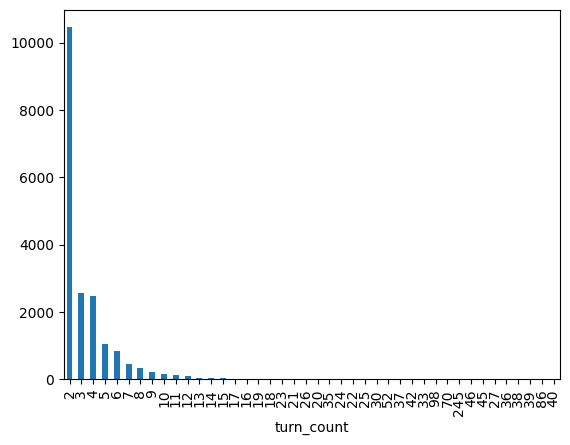

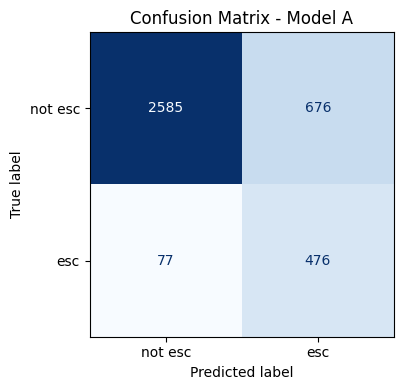

In [293]:
#confusion matrix 
cm = confusion_matrix(y_test, y_pred)
print("=== confusion matrix ===")
print(cm)

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm, display_labels=["not esc", "esc"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Confusion Matrix - Model A")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

=== ROC-AUC: 0.8969 ===


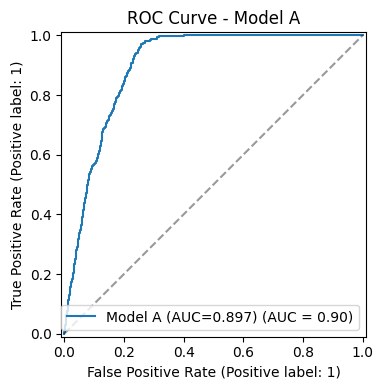

In [294]:
#roc-auc
auc = roc_auc_score(y_test, y_proba)
print(f"=== ROC-AUC: {auc:.4f} ===")

fig, ax = plt.subplots(figsize=(5, 4))
RocCurveDisplay.from_predictions(y_test, y_proba, ax=ax, name=f"Model A (AUC={auc:.3f})")
ax.plot([0, 1], [0, 1], "k--", alpha=0.4)   # random baseline
ax.set_title("ROC Curve - Model A")
plt.tight_layout()
plt.savefig("roc_curve.png", dpi=150)
plt.show()

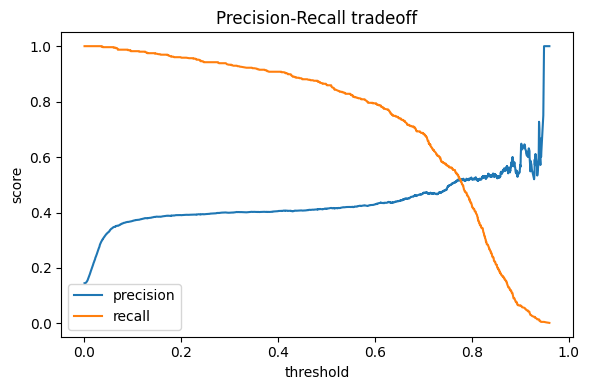

best F1 threshold: 0.413


In [302]:
from sklearn.metrics import precision_recall_curve

prec, rec, thr = precision_recall_curve(y_test, y_proba)

plt.figure(figsize=(6, 4))
plt.plot(thr, prec[:-1], label="precision")
plt.plot(thr, rec[:-1], label="recall")
plt.xlabel("threshold")
plt.ylabel("score")
plt.title("Precision-Recall tradeoff")
plt.legend()
plt.tight_layout()
plt.savefig("pr_tradeoff.png", dpi=150)
plt.show()

f1s = 2 * prec * rec / (prec + rec + 1e-9)
best_thr = thr[f1s.argmax()]
print(f"best F1 threshold: {best_thr:.3f}")

In [295]:
# cross-validation
# run on the full scaled feature set
print("=== 5-fold stratified CV (AUC) ===")

x_all = pd.concat([x_train_scaled, x_test_scaled])
y_all = pd.concat([y_train, y_test])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_model = XGBClassifier(scale_pos_weight=spw, **parameters)
cv_scores = cross_val_score(cv_model, x_all, y_all, cv=cv, scoring="roc_auc", n_jobs=-1)

print(f"fold AUCs: {np.round(cv_scores, 4)}")
print(f"mean: {cv_scores.mean():.4f}  std: {cv_scores.std():.4f}")

=== 5-fold stratified CV (AUC) ===
fold AUCs: [0.8976 0.9006 0.8967 0.8978 0.891 ]
mean: 0.8968  std: 0.0031


shap values shape: (3814, 21)


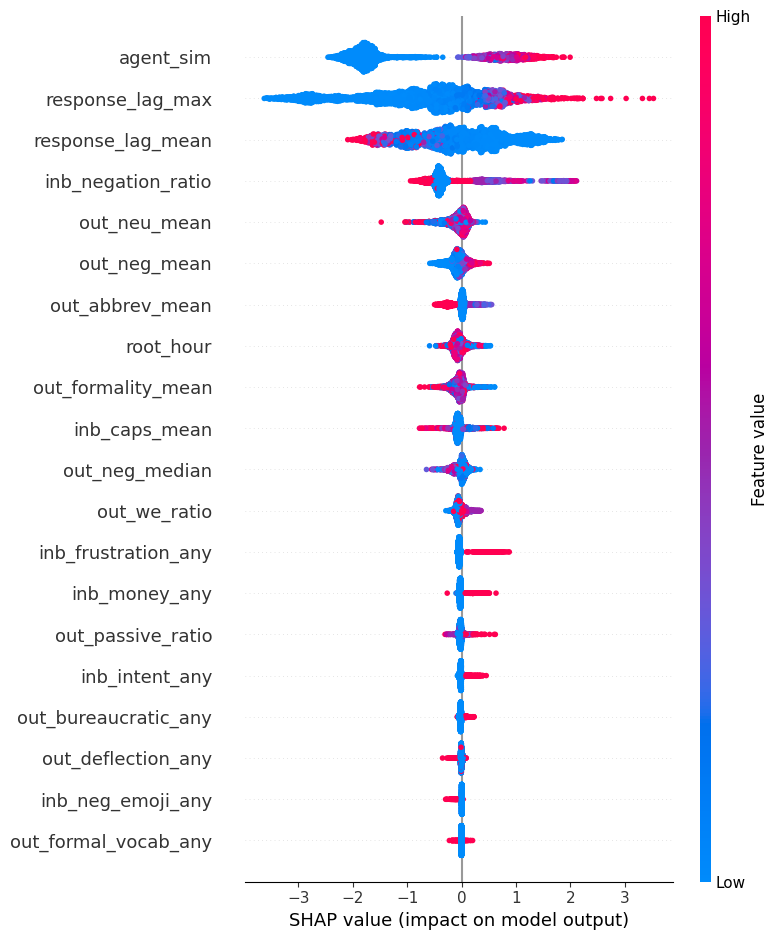

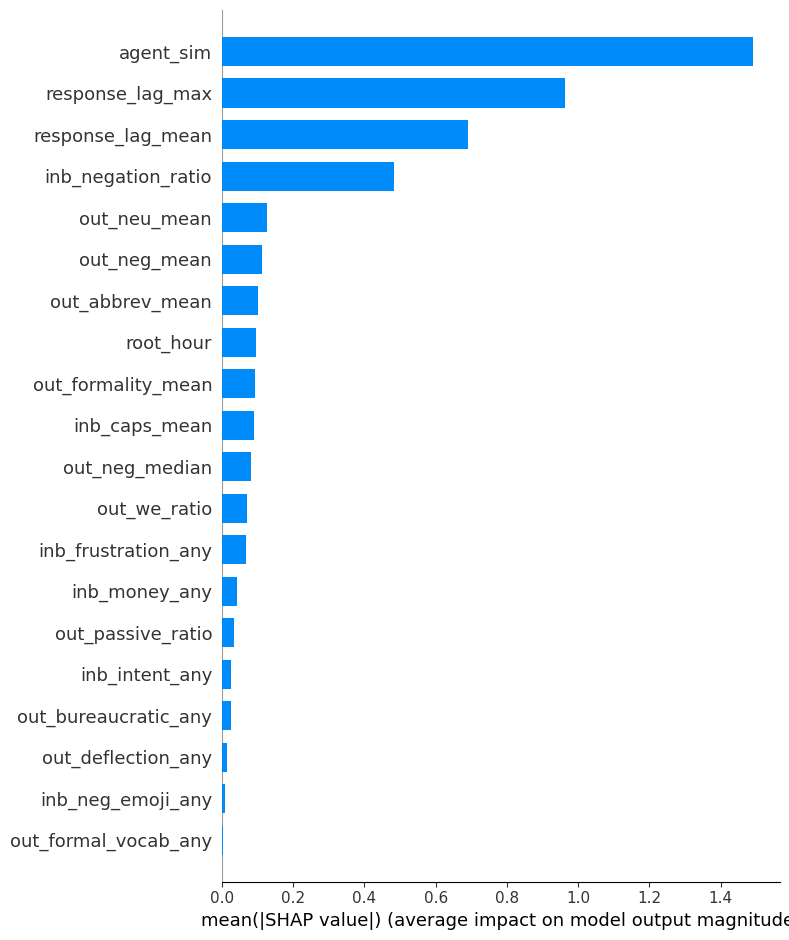


=== SHAP feature ranking ===
             feature  mean_abs_shap
           agent_sim          1.492
    response_lag_max          0.964
   response_lag_mean          0.691
  inb_negation_ratio          0.482
        out_neu_mean          0.127
        out_neg_mean          0.114
     out_abbrev_mean          0.102
           root_hour          0.096
  out_formality_mean          0.094
       inb_caps_mean          0.091
      out_neg_median          0.081
        out_we_ratio          0.070
 inb_frustration_any          0.068
       inb_money_any          0.043
   out_passive_ratio          0.034
      inb_intent_any          0.027
out_bureaucratic_any          0.025
  out_deflection_any          0.014
   inb_neg_emoji_any          0.009
out_formal_vocab_any          0.004
out_contraction_mean          0.000

waterfall for test row 24 (true positive)


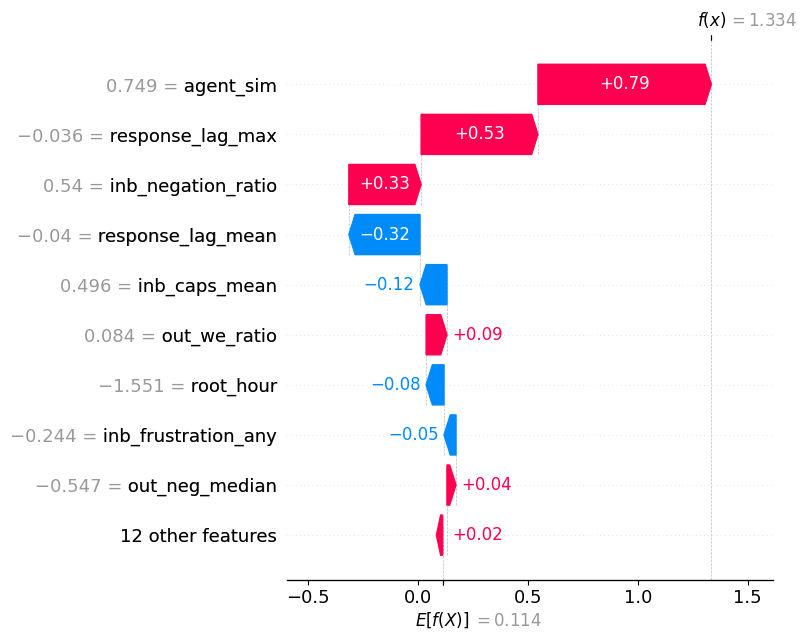

In [296]:
import shap


explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(x_test_scaled)

print("shap values shape:", shap_values.shape)


# summary plot - global feature importance
plt.figure()
shap.summary_plot(shap_values, x_test_scaled, show=False)
plt.tight_layout()
plt.savefig("shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

#bar version
plt.figure()
shap.summary_plot(shap_values, x_test_scaled, plot_type="bar", show=False)
plt.tight_layout()
plt.savefig("shap_bar.png", dpi=150, bbox_inches="tight")
plt.show()


#ranked importance as a table
mean_abs = np.abs(shap_values).mean(axis=0)
shap_rank = pd.DataFrame({
    "feature": x_test_scaled.columns,
    "mean_abs_shap": mean_abs,
}).sort_values("mean_abs_shap", ascending=False).reset_index(drop=True)

print("\n=== SHAP feature ranking ===")
print(shap_rank.to_string(index=False))


# waterfall
tp_mask = (y_test.values == 1) & (y_pred == 1)
tp_idx  = np.where(tp_mask)[0][0] 

print(f"\nwaterfall for test row {tp_idx} (true positive)")
plt.figure()
shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[tp_idx],
        base_values=explainer.expected_value,
        data=x_test_scaled.iloc[tp_idx],
        feature_names=list(x_test_scaled.columns),
    ),
    show=False,
)
plt.tight_layout()
plt.savefig("shap_waterfall.png", dpi=150, bbox_inches="tight")
plt.show()

# 12. Artifact extraction

In [297]:
import json
import os

tweets = tweets_scored      
threads = df_threads
N_ROOTS = 300
N_MIDDLES = 300
SEED = 42
OUT = "artifacts"
os.makedirs(OUT, exist_ok=True)

label_by_root = dict(zip(threads["thread_root"], threads["escalated"]))

# group tweets into ordered turn lists
grouped = {}
for tid, g in tweets.sort_values("turn_index").groupby("thread_root"):
    grouped[tid] = [
        {"inbound": bool(r.inbound), "text": str(r.text)}
        for r in g.itertuples()
    ]

all_ids = [t for t in grouped if t in label_by_root]

import random
random.seed(SEED)

# Mode 1: roots whose first turn is inbound (a real customer opener)
root_candidates = [
    t for t in all_ids
    if grouped[t] and grouped[t][0]["inbound"]
]
roots_sample = random.sample(root_candidates, min(N_ROOTS, len(root_candidates)))
roots = [
    {
        "thread_root": t,
        "opening_text": grouped[t][0]["text"],
    }
    for t in roots_sample
]

# Mode 2: threads with >= 4 turns following customer -> company -> customer -> ...
middle_candidates = []
for t in all_ids:
    turns = grouped[t]
    if len(turns) < 4:
        continue
    # require the canonical opening pattern: inbound, outbound, inbound
    if turns[0]["inbound"] and (not turns[1]["inbound"]) and turns[2]["inbound"]:
        middle_candidates.append(t)

middles_sample = random.sample(middle_candidates, min(N_MIDDLES, len(middle_candidates)))
middles = [
    {
        "thread_root": t,
        "prompt_turns": grouped[t][:3],          # what the user sees
        "real_continuation": grouped[t][3:],     # the reveal
        "escalated": int(label_by_root[t]),      # the outcome
    }
    for t in middles_sample
]

payload = {"roots": roots, "middles": middles}
with open(os.path.join(OUT, "predictor_threads.json"), "w", encoding='utf-8') as f:
    json.dump(payload, f, ensure_ascii=False, indent=2)

print(f"roots: {len(roots)} (from {len(root_candidates)} candidates)")
print(f"middles: {len(middles)} (from {len(middle_candidates)} candidates)")
print("wrote artifacts/predictor_threads.json")

roots: 300 (from 19067 candidates)
middles: 300 (from 4491 candidates)
wrote artifacts/predictor_threads.json


In [298]:
import joblib

OUT = "artifacts"
os.makedirs(OUT, exist_ok=True)

model_a.save_model(os.path.join(OUT, "model.json"))
joblib.dump(scaler, os.path.join(OUT, "scaler.pkl"))

with open(os.path.join(OUT, "feature_columns.json"), "w") as f:
    json.dump(list(x.columns), f, indent=2)

print(f"wrote {len(x.columns)} feature columns")
print("artifacts/model.json, artifacts/scaler.pkl, artifacts/feature_columns.json")

wrote 21 feature columns
artifacts/model.json, artifacts/scaler.pkl, artifacts/feature_columns.json


In [299]:
OUT = "artifacts"
os.makedirs(OUT, exist_ok=True)
ALPHA = 0.0025  # Bonferroni-adjusted (20 tests)

esc = df_threads[df_threads["escalated"] == 1]
non = df_threads[df_threads["escalated"] == 0]
n_total = len(df_threads)


def rank_biserial(g1, g2, u):
    return 1 - (2 * u) / (len(g1) * len(g2))


def cramers_v(chi2, n, shape):
    return float(np.sqrt(chi2 / (n * min(shape[0] - 1, shape[1] - 1))))


BINARY = [
    ("out_deflection_any",   "Deflection language (agent)"),
    ("out_bureaucratic_any", "Bureaucratic language (agent)"),
    ("inb_frustration_any",  "Frustration terms (customer)"),
    ("inb_intent_any",       "Intent terms (customer)"),
    ("out_formal_vocab_any", "Formal vocabulary (agent)"),
    ("inb_neg_emoji_any",    "Negative emoji (customer)"),
]

CONTINUOUS = [
    ("agent_sim",          "Agent template similarity"),
    ("response_lag_max",   "Max response lag (min)"),
    ("response_lag_mean",  "Mean response lag (min)"),
    ("out_passive_ratio",  "Passive voice ratio (agent)"),
    ("inb_negation_ratio", "Negation ratio (customer)"),
    ("inb_caps_mean",      "Caps ratio (customer)"),
    ("out_we_ratio",       "We-not-I ratio (agent)"),
    ("out_formality_mean", "Formality F-score (agent)"),
]

DIST = ["agent_sim", "response_lag_max", "inb_negation_ratio"]

binary_drivers = []
for f, label in BINARY:
    table = __import__("pandas").crosstab(df_threads["escalated"], df_threads[f])
    chi2, p, _, _ = chi2_contingency(table)
    binary_drivers.append({
        "feature": f, "label": label,
        "esc_rate": round(float(esc[f].mean()), 4),
        "non_rate": round(float(non[f].mean()), 4),
        "cramers_v": round(cramers_v(chi2, n_total, table.shape), 4),
        "p_value": float(p), "significant": bool(p < ALPHA),
    })

continuous_drivers = []
for f, label in CONTINUOUS:
    u, p = mannwhitneyu(esc[f], non[f], alternative="two-sided")
    continuous_drivers.append({
        "feature": f, "label": label,
        "esc_median": round(float(esc[f].median()), 4),
        "non_median": round(float(non[f].median()), 4),
        "rank_biserial": round(float(rank_biserial(esc[f], non[f], u)), 4),
        "p_value": float(p), "significant": bool(p < ALPHA),
    })


def box_stats(s):
    q1, med, q3 = np.percentile(s, [25, 50, 75])
    return {"q1": round(float(q1), 4), "median": round(float(med), 4),
            "q3": round(float(q3), 4), "mean": round(float(s.mean()), 4),
            "lo": round(float(s.min()), 4), "hi": round(float(s.quantile(0.95)), 4)}


distributions = []
for f in DIST:
    label = dict(CONTINUOUS).get(f, f)
    distributions.append({
        "feature": f, "label": label,
        "esc": box_stats(esc[f]), "non": box_stats(non[f]),
    })

# test-set predictions for the ROC + threshold/confusion view
yt = np.asarray(y_test).astype(int).tolist()
yp = [round(float(v), 4) for v in np.asarray(y_proba)]

try:
    shap_panel = [
        {"feature": r.feature, "mean_abs_shap": round(float(r.mean_abs_shap), 5)}
        for r in shap_rank.itertuples()
    ][:15]
except Exception:
    shap_panel = None

from sklearn.metrics import roc_auc_score
auc = float(roc_auc_score(yt, yp))

payload = {
    "source": "real",
    "kpis": {
        "threads": int(n_total),
        "escalated": int((df_threads["escalated"] == 1).sum()),
        "esc_rate": round(float(df_threads["escalated"].mean()), 4),
        "auc": round(auc, 4),
    },
    "binary_drivers": binary_drivers,
    "continuous_drivers": continuous_drivers,
    "distributions": distributions,
    "eval": {"y_true": yt, "y_proba": yp, "auc": round(auc, 4)},
    "shap": shap_panel,
}

with open(os.path.join(OUT, "dashboard_data.json"), "w") as f:
    json.dump(payload, f)

print(f"wrote artifacts/dashboard_data.json  ({len(yt)} test points, "
      f"{len(binary_drivers)} binary + {len(continuous_drivers)} continuous drivers, "
      f"shap={'yes' if shap_panel else 'no'})")

wrote artifacts/dashboard_data.json  (3814 test points, 6 binary + 8 continuous drivers, shap=yes)


In [300]:
d = json.load(open("artifacts/dashboard_data.json"))
print("shap in file:", d["shap"] if d["shap"] is None else f"{len(d['shap'])} rows")
print("shap_rank defined in notebook:", 'shap_rank' in dir())

shap in file: 15 rows
shap_rank defined in notebook: True
